In [2]:
# imports
import simpy
import numpy as np
import sys
import pandas as pd
import os
from IPython.display import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import time
sys.path.append('../code/pycharm')
from single_station_transient import *
from utils import *

## Transient analysis

<div dir="rtl">

### עד כה ניתחנו מערכות סטציונריות. כלומר מערכות שלא משתנות עם הזמן ומעניין אותי מה קורה בשלב שהמערכת התייצבה. בפועל זה אומר שהתפלגות זמני המתנה או מספר צרכנים במערכת לא משתנה. 
    
###  המציאות היא כזאת שמערכות משתנות עם הזמן  ולא מגיעות להתייצבות. במקרה כזה אנחנו נרצה לדעת את אורך התור או זמני המתנה כפונקציה של הזמן. 
    
### אבל איך עושים את זה? עד עכשיו ניתחנו את המערכת במצב יציב ולא כפונקציה של הזמן. 

##  בתרגול הזה נלמד את המנגנון שבוא אנחנו בונים סימולציה טרנזיאנטית

### נתמקד בחישוב מספר הצרכנים במערכת כרגע. הרעיון הכללי לחשב את ההתפלגות הזאת לאורך זמן.

### בשביל זה צריך לדעת מה ההסתברות ל0,1,2 או יותר צרכנים בכל יחידת זמן. 

### נתמקד בשאלה פשוטה יותר קודם, כיצד נדע מה ההסתברות ל-3 צרכנים אחרי 10 דקות?

### תשובה: נריץ סימולציה למשך 10 דקות, ונבדוק כמה צרכנים האם היו 3 צרכנים או לא היו 3 צרכנים. 

### אם יצא שכן? מה זה אומר? האם בודאות יהיו 3 צרכנים אחרי 10 דקות? מובן שלא. נרצה להריץ את אותן 10 דקות הרבה פעמים ולבדוק את פרופרציוןת הפעמים שהיו 3 צרכנים.

### למשל: נניח הרצנו את הסימולציה 100 פעם ויצא ב42  מהמקרים היו 3 צרכנים ו58 מקרים שהיה מספר שונה. 

### נעריך כי ההסתברות ל-3 צרכנים בt = 10 היא 0.42. 

### באותה צורה נעשה עבור כל מספר אפשרי של מספר צרכנים ועבור כל יחידת זמן שמעניינת אותנו. 

### בשביל הפשטות נניח כי גם זמנים בין הגעות וגם זמני שירות מפולגים מעריכית.

# בניית event log:

## אם נרצה לדעת כמה צרכנים יש בכל מיני נוקודת בזמן - כדאי לנו לבנות יומן ארועים ולתעד אותו. 

### מה זה אומר בדיוק? בכל פעם שיש שינוי במספר הצרכנים במערכת - כלומר הגעה או סיום שירות.

### בעצם בכל פעם שיש שינוי במספר הצרכנים נרצה לתעד כמה צרכנים יש במערכת, מה היה השינוי מה הזמן במערכת. 

### את יומן הארועים נבנה בdataframe. יהיו 3 עמודות:

#### Time_stamp: מתי הארוע קרה.

#### Type: האם היית הגעה או סיום שירות

#### num_cust: מספר צרכנים במערכת ברגע השינוי.

### הערה: נוסיף עמודה שמציינת את מספר הסידורי של הצרכן כדי שיהיה יותר קל לנטר את המערכת. 

### עניין טכני: במקום לבנות את הdataframe על המקום נבנה 4 Lists ובסוף נמיר אותם לdf

In [3]:
class Trans_single_rate:

    def __init__(self, lamda, mu, sim_time):

        self.env = simpy.Environment() # initializing simpy enviroment 
        self.server = simpy.Resource(self.env, capacity=1) # Defining a resource with capacity 1
        self.end_time = sim_time # The time simulation terminate
        self.id_current = 1 # keeping track of cusotmers id
        self.df_events = pd.DataFrame([]) # is a dataframe the holds all information of the queue dynamic:
        #an event can one of three: (1. arrival, 2. entering service 3. service completion)
        
        self.mu = mu # service rate
        self.lamda = lamda # arrival rate
        self.num_cust_sys = 0 # keeping track of number of customers in the system
                
        self.event_log_customer_id_list = []
        self.event_log_num_cust_list = []
        self.event_log_type_list = []
        self.event_log_time_stamp = []
                
    def run(self):

        self.env.process(self.customer_arrivals()) ## Initializing a process
        self.env.run(until=self.end_time) ## Running the simulaiton until self.end_time

   
    
    def give_rate_per_time(self, time):
        
        ind_rate = self.arrival_pd.loc[self.arrival_pd['LB_time']<=time, :].index[-1]
        return self.arrival_pd.loc[ind_rate, 'arrival_rate']
        
    
    #########################################################
    ################# Service block ######################### 
    ######################################################### 
    
    
    def service(self, customer):

        with self.server.request() as req:
                       

            yield req

            yield self.env.timeout(np.random.exponential(1/self.mu))


            #we compute how much time the system had this number of customers
            
            self.num_cust_sys -= 1 # updating number of cusotmers in the system
 
            self.event_log_customer_id_list.append(customer.id)
            self.event_log_time_stamp.append(self.env.now)
            self.event_log_num_cust_list.append(self.num_cust_sys)
            self.event_log_type_list.append('Departure')
                       

           

    #########################################################
    ################# Arrival block ######################### 
    ######################################################### 
    
    
    def customer_arrivals(self):

        while True:

            yield self.env.timeout(np.random.exponential(1/self.lamda))


            
            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id,  arrival_time, 1)
            
            self.event_log_customer_id_list.append(customer.id) 
            self.event_log_time_stamp.append(self.env.now)
            
      
            
            self.num_cust_sys += 1
            self.event_log_num_cust_list.append(self.num_cust_sys)
            self.event_log_type_list.append('Arrival')

            self.id_current += 1



            self.env.process(self.service(customer))
            

<div dir="rtl">

## נריץ סימולציה בודדת:

In [4]:
lamda = 1
mu  = 1
sim_time = 5


sim_time +=1
sim_instance = Trans_single_rate(lamda, mu, sim_time)
sim_instance.run()

<div dir="rtl">

### נבנה את היומן ארועים

In [5]:
event_log = pd.DataFrame({'Customer_id': sim_instance.event_log_customer_id_list,
                                  'Time_stamp': sim_instance.event_log_time_stamp,
                                  'Type': sim_instance.event_log_type_list,
                                  'num_cust': sim_instance.event_log_num_cust_list})

In [6]:
event_log

,Customer_id,Time_stamp,Type,num_cust
0,1,0.690195,Arrival,1
1,1,0.898645,Departure,0
2,2,1.222344,Arrival,1
3,3,1.435723,Arrival,2
4,2,1.525600,Departure,1
5,4,1.829785,Arrival,2
6,5,1.978428,Arrival,3
7,3,2.117312,Departure,2
8,4,2.526304,Departure,1
9,5,3.014312,Departure,0


<div dir="rtl">

### עכשיו נחלץ בכל דקה עגולה כמה צרכנים היו

### בשביל זה נשתמש בפונקציה find_num_cust_time_stamp



In [7]:
def find_num_cust_time_stamp(df, time):
    try:
        ind = df.loc[df['Time_stamp'] < time, :].index[-1]

        num_cust = df.loc[ind, 'num_cust']
    except:
        num_cust = 0
        
    return num_cust

In [23]:
result = [(time_epoch, find_num_cust_time_stamp(event_log, time_epoch)) for time_epoch in range(sim_time)]

In [24]:
result

[(0, 0),
 (1, np.int64(4)),
 (2, np.int64(2)),
 (3, np.int64(2)),
 (4, np.int64(4)),
 (5, np.int64(3))]

<div dir="rtl">

### כלומר בסימולציה הנוכחית בזמן 0 היו 0 צרכנים. 
### זה ברור כי התחלנו עם 0 צרכנים במערכת.

### בזמן 1 היו 4 צרכנים. בזמן 2 היו 2. וכך הלאה. 

### אם נריץ שוב, לאו דווקא נקבל את אותה תוצאה:

In [8]:
lamda = 1
mu  = 1
sim_time = 5


sim_time +=1
sim_instance = Trans_single_rate(lamda, mu, sim_time)
sim_instance.run()

event_log = pd.DataFrame({'Customer_id': sim_instance.event_log_customer_id_list,
                                  'Time_stamp': sim_instance.event_log_time_stamp,
                                  'Type': sim_instance.event_log_type_list,
                                  'num_cust': sim_instance.event_log_num_cust_list})

result = [(time_epoch, find_num_cust_time_stamp(event_log, time_epoch)) for time_epoch in range(sim_time)]

result

[(0, 0),
 (1, np.int64(4)),
 (2, np.int64(7)),
 (3, np.int64(6)),
 (4, np.int64(6)),
 (5, np.int64(6))]

<div dir="rtl">

### אכן תוצאות מעט שונות.

### אם נסתכל על הפעם הראשונה השרצנו בזמן 5 היו 3 צרכנים ואילו בפעם השניה היו 2.

### אם היינו עושים הסקה רק על סמך 2 הסימולציות האלו היינו טוענים בהסתברות 0.5 יהיו 2 צרכנים ובהסתברות 0.5 יהיו 3. כל ערך אחר בהסתברות 0. 

### רק אם נריץ "הרבה" נוכל לקבל אומד מדויק. 

### עכשיו נעשה הרבה סימולציות ונחשב את הפרופרציות למספר הצרכנים לכל יחידת זמן. 

### נעשה את בצורה הבאה: נחשב מילון לכל סימולציה באופן הבא:

In [9]:
resultDictionary = dict((x, y) for x, y in result)
resultDictionary

{0: 0,
 1: np.int64(4),
 2: np.int64(7),
 3: np.int64(6),
 4: np.int64(6),
 5: np.int64(6)}

<div dir="rtl">

### כלומר המפתחות של המילון זה היחידות זמן והערכים שלהם זה כמות הצרכנים באותה יחידת זמן. 

### כעת נעטוף את כל הקוד הזה לפונקציה אחת:



In [10]:
def single_sim_single_rate(arrivals, mu, sim_time):
    sim_time +=1
    sim_instance = Trans_single_rate(arrivals, mu, sim_time)
    sim_instance.run()
    event_log = pd.DataFrame({'Customer_id': sim_instance.event_log_customer_id_list,
                                  'Time_stamp': sim_instance.event_log_time_stamp,
                                  'Type': sim_instance.event_log_type_list,
                                  'num_cust': sim_instance.event_log_num_cust_list})
    
    result = [(time_epoch, find_num_cust_time_stamp(event_log, time_epoch)) for time_epoch in range(sim_time)]
    resultDictionary = dict((x, y) for x, y in result)
    
    return resultDictionary



<div dir="rtl">

    
### נעשה עכשיו 5000 סימולציות ונחשב ססטיטיקות של כמה צרכנים היו בכל רגע נתון. 

In [11]:
list_of_sims = []
for ind in tqdm(range(5000)):
    list_of_sims.append(single_sim_single_rate(lamda, mu, sim_time))
    

100%|█████████████████████████████████████████████████████████████████████████████████| 5000/5000 [00:27<00:00, 184.63it/s]


<div dir="rtl">

### נניח שאני ארצה לחשב את ההתפלגות של מספר הצרכנים במערכת ברגע 5. כרגע תוצאת הסימולציה מראה לי כמה צרכנים היו בכל אחת מהסימולציות ברגע 5. אבל אני רוצה לדעת את השכיחות היחסית של מספר הצרכנים מבין כל הסימולציות. זה יקנה לי את ההתפלגות המיוחלת.
    
### בשביל לדעת שכיחות יחסית נעשה זאת בשני שלבים:
### 1. נחשב כמה פעמים היו 0, 1,2, ... צרכנים וכולי...
### 2. אחרי שחישבנו את השכיחות בסעיף 1, נחלק את הכל בסכום הכולל ונקבל את השכיחות היחסית.
    


<div dir="rtl">

##    נרצה לדעת כמה צרכנים יכולים להיות במערכת. כלומר מה המקסימום. נחשב את הערך הכי גבוה שהתקבל. 
    


In [12]:
vals_at_5 = [dict_[5] for dict_ in list_of_sims]
vals_at_5_arr = np.array(vals_at_5)

vals_at_5_arr.max()

np.int64(12)

<div dir="rtl">

## כל ערך בוקטור מראה לי כמה צרכנים היו ברגע אחר מכל פעם שהרצית את הסימולציה. 

### נגיד אם נספור כמות הפעמים שהיה צרכן אחד בדיוק:

In [13]:
(vals_at_5_arr==1).sum()

np.int64(1158)

<div dir="rtl">

### מסה"כ: 



In [14]:
vals_at_5_arr.shape[0]

5000

<div dir="rtl">

### כלומר הפרופרציות הן:



In [15]:
(vals_at_5_arr==1).sum()/vals_at_5_arr.shape[0]

np.float64(0.2316)

<div dir="rtl">

### כדי לחשב את השכיחות נעשה dictionary שהמפתחות זה מספר הצרכנים במערכת והערך שלהם הוא כמה פעמים היה. בהתחלה נאתחל את הכל ב-0 ולאחר מכן נעבור על הסימולציות ונסכום עבור כל מספר צרכנים אפשרי כמה היה סה"כ.

In [16]:
max_num_customers = vals_at_5_arr.max() ## מספר המקסימלי האפשרי

time_dict_5 = np.zeros(max_num_customers)

<div dir="rtl">

### עכשיו נרצה לעשות את זה עבור מספר אפשרי של הצרכנים

In [17]:
probs_at_5 = []

for num_cust in range(max_num_customers+1):

    probs_at_5.append((vals_at_5_arr == num_cust).mean())

probs_at_5_arr = np.array(probs_at_5)

<div dir="rtl">

#### סיימנו את חלק 1, לחשב את השכיחויות. נעבר לחשב את השכיחות היחסית. 

In [18]:
probs_at_5_arr

array([2.548e-01, 2.316e-01, 1.814e-01, 1.312e-01, 9.080e-02, 5.840e-02,
       2.760e-02, 1.240e-02, 8.000e-03, 2.400e-03, 1.000e-03, 2.000e-04,
       2.000e-04])

C:\Users\Eshel\AppData\Local\Temp\ipykernel_19876\2536044102.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax1.legend(fontsize=22)


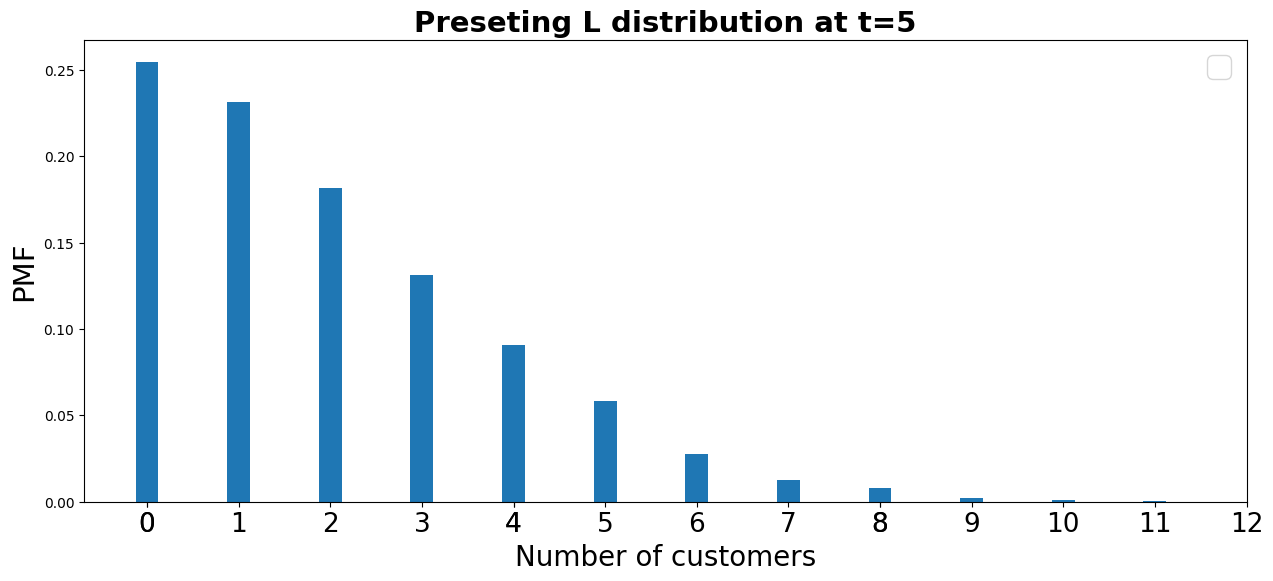

In [19]:
## Plotting the graph

fig, (ax1) = plt.subplots(1, 1, figsize=(15, 6))
width = 0.25
max_probs = max_num_customers
rects1 = ax1.bar(np.arange(max_probs), probs_at_5_arr[:max_probs], width)
plt.rcParams['font.size'] = '20'

# # Add some text for labels, title and custom x-axis tick labels, etc.
ax1.set_ylabel('PMF', fontsize=21)
ax1.set_xlabel('Number of customers', fontsize=20)
ax1.set_title( 'Preseting L distribution at t=5' , fontsize=21, fontweight="bold")
ax1.set_xticks(np.linspace(0,12,16).astype(int))
ax1.set_xticklabels(np.linspace(0,12,16).astype(int), fontsize=19)
ax1.legend(fontsize=22)
plt.show()

In [20]:
prob_more_than_10 = probs_at_5_arr[11:].sum()
prob_more_than_10

np.float64(0.0004)

<div dir="rtl">

## כאשר עשינו ניתוח בשיווי משקל דרשנו יציבות.

### פירוש הדבר שקצב הגעה צריך להיות קטן מקצב שירות. 

### בנוסף אנחנו מניחים שהתפלגות הגעה ושירות חייבים להיות קבועים בזמן. 

### בניתוח טרנזיאנטי אין לנו צורך באף אחת מההנחות האלה. 

### כעת נעבור לניתוח שקצב ההגעה משתנה

## לפנינו קצב הגעה לפי שעות ביום. 

### כלומר בין חצות ל12:00 בצהריים קצב הגעה הוא 1. בין 12:00 ל20:00 הקצב הוא 0.5 ואילו קצב ההגעה בין 20:00 לחצות הוא 0.9

In [79]:
dict_sch = {0:1, 12:0.5,20:0.9}

arrival_scd_pd = convert_dict_to_pd(dict_sch)
arrival_scd_pd

,LB_time,arrival_rate
0,0.0,1.0
1,12.0,0.5
2,20.0,0.9


<div dir="rtl">

## אם נפרוט את זה לכל השעות בשבוע:

In [53]:
rates = []
for hour in range(24):
    rates.append(give_rate_per_time(arrival_scd_pd,  hour))

rates

[np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(1.0),
 np.float64(0.5),
 np.float64(0.5),
 np.float64(0.5),
 np.float64(0.5),
 np.float64(0.5),
 np.float64(0.5),
 np.float64(0.5),
 np.float64(0.5),
 np.float64(0.9),
 np.float64(0.9),
 np.float64(0.9),
 np.float64(0.9)]

<div dir="rtl">

### ויזואלית זה נראה כך:

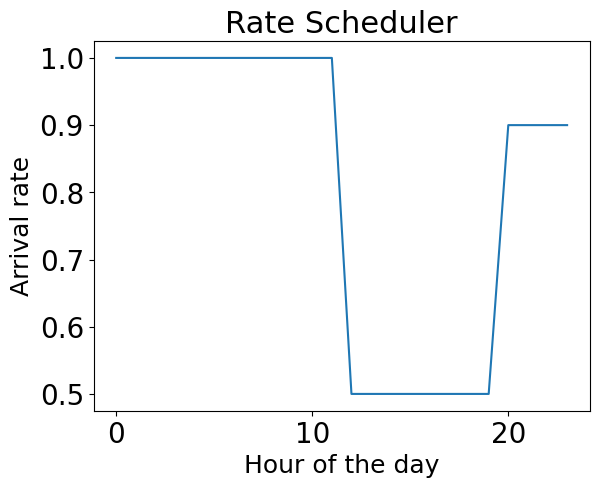

In [51]:
plt.figure()
plt.plot(np.arange(24), rates)
plt.xlabel('Hour of the day', fontsize = 18)
plt.ylabel('Arrival rate', fontsize = 18)
plt.title('Rate Scheduler', fontsize = 22)
plt.show()


<div dir="rtl">


    
### בניגוד למקרה הקודם קצבי הגעה יכולים להשתנות. מכניסים למערכת pandas dataframe שמציין את השעה שיש שינוי קצב ומה הקצב. למשל: 

In [73]:
dict_sch = {0:1, 12:0.5,20:0.9}
arrival_scd_pd = convert_dict_to_pd(dict_sch)
arrival_scd_pd

,LB_time,arrival_rate
0,0.0,1.0
1,12.0,0.5
2,20.0,0.9


<div dir="rtl">

### כעת בונים מחלקה חדשה שמקבלת את הdataframe המתאר את הקצבים לפני זמנים

In [21]:
class Queue_single_station:

    def __init__(self, arrival_scd_pd, mu, sim_time):

        self.env = simpy.Environment() # initializing simpy enviroment 
        self.server = simpy.Resource(self.env, capacity=1) # Defining a resource with capacity 1
        self.end_time = sim_time # The time simulation terminate
        self.id_current = 1 # keeping track of cusotmers id
        self.df_events = pd.DataFrame([]) # is a dataframe the holds all information of the queue dynamic:
        #an event can one of three: (1. arrival, 2. entering service 3. service completion)
        
        self.df_waiting_times = pd.DataFrame([]) # is a dataframe the holds all information waiting time
        self.mu = mu # service rate
        self.num_cust_sys = 0 # keeping track of number of customers in the system
        
        
        self.event_log_customer_id_list = []
        self.event_log_num_cust_list = []
        self.event_log_type_list = []
        self.event_log_time_stamp = []
        
        self.arrival_pd = arrival_scd_pd

    def run(self):

        self.env.process(self.customer_arrivals()) ## Initializing a process
        self.env.run(until=self.end_time) ## Running the simulaiton until self.end_time

   
    
    def give_rate_per_time(self, time):
        
        ind_rate = self.arrival_pd.loc[self.arrival_pd['LB_time']<=time, :].index[-1]
        return self.arrival_pd.loc[ind_rate, 'arrival_rate']
        
    
    #########################################################
    ################# Service block ######################### 
    ######################################################### 
    
    
    def service(self, customer):

        with self.server.request() as req:
                       
            yield req

            yield self.env.timeout(np.random.exponential(1/self.mu))

            tot_time = self.env.now - self.last_event_time  # keeping track of the last event
            #we compute how much time the system had this number of customers
            
            self.num_cust_sys -= 1 # updating number of cusotmers in the system

            self.event_log_customer_id_list.append(customer.id)
            self.event_log_time_stamp.append(self.env.now)
            self.event_log_num_cust_list.append(self.num_cust_sys)
            self.event_log_type_list.append('Departure')
     
    #########################################################
    ################# Arrival block ######################### 
    ######################################################### 
    
    
    def customer_arrivals(self):

        while True:

            arrival_rate = self.give_rate_per_time(self.env.now)
            
            yield self.env.timeout(np.random.exponential(1/arrival_rate))


            
            curr_id = self.id_current
            arrival_time = self.env.now
            customer = Customer(curr_id,  arrival_time, 1)
            
            self.event_log_customer_id_list.append(customer.id)
            self.event_log_time_stamp.append(self.env.now)
            
            self.last_event_time = self.env.now
            self.last_time = self.env.now         
            
            self.num_cust_sys += 1
            self.event_log_num_cust_list.append(self.num_cust_sys)
            self.event_log_type_list.append('Arrival')

            self.id_current += 1
            self.env.process(self.service(customer))

<div dir="rtl">

### בעצם מה ששונה זה שהתפלגות הגעה היא משתנה עם הזמן. 

### צריך בעצם בהינתן שעה ביום להגריל לפי הקצב הנוכחי

### נכשה זאת בעזרת פונקציה: 



### arrival_rate = self.give_rate_per_time(self.env.now)) 

In [74]:
arrival_scd_pd

,LB_time,arrival_rate
0,0.0,1.0
1,12.0,0.5
2,20.0,0.9


<div dir="rtl">

### בעצם הפונקציה מקבלת את הזמן של הסימולציה ומוצאת את הזמן שבו הקצב החדש התחיל

In [ ]:
def give_rate_per_time(self, time):
        
    ind_rate = self.arrival_pd.loc[self.arrival_pd['LB_time']<=time, :].index[-1]
    return self.arrival_pd.loc[ind_rate, 'arrival_rate']

In [81]:
time = 3

arrival_scd_pd.loc[arrival_scd_pd['LB_time']<=time, :]

,LB_time,arrival_rate
0,0.0,1.0


In [82]:
time = 14

arrival_scd_pd.loc[arrival_scd_pd['LB_time']<=time, :]

,LB_time,arrival_rate
0,0.0,1.0
1,12.0,0.5


In [83]:
time = 22

arrival_scd_pd.loc[arrival_scd_pd['LB_time']<=time, :]

,LB_time,arrival_rate
0,0.0,1.0
1,12.0,0.5
2,20.0,0.9


In [84]:
dict_sch = {0:1, 12:0.5,20:0.9}
sim_time = 24 
arrival_scd_pd = convert_dict_to_pd(dict_sch)

sim_time = 24

sim_time +=1
queue_single_station = Queue_single_station(arrival_scd_pd, mu, sim_time)
queue_single_station.run()
event_log = pd.DataFrame({'Customer_id': queue_single_station.event_log_customer_id_list,
                              'Time_stamp': queue_single_station.event_log_time_stamp,
                              'Type': queue_single_station.event_log_type_list,
                              'num_cust': queue_single_station.event_log_num_cust_list})

result = [(time_epoch, find_num_cust_time_stamp(event_log, time_epoch)) for time_epoch in range(sim_time)]
resultDictionary = dict((x, y) for x, y in result)

resultDictionary

{0: 0,
 1: 0,
 2: 0,
 3: np.int64(2),
 4: np.int64(1),
 5: np.int64(0),
 6: np.int64(0),
 7: np.int64(1),
 8: np.int64(0),
 9: np.int64(1),
 10: np.int64(4),
 11: np.int64(4),
 12: np.int64(2),
 13: np.int64(1),
 14: np.int64(0),
 15: np.int64(1),
 16: np.int64(0),
 17: np.int64(1),
 18: np.int64(1),
 19: np.int64(2),
 20: np.int64(0),
 21: np.int64(1),
 22: np.int64(1),
 23: np.int64(3),
 24: np.int64(2)}

<div dir="rtl">


### נעטוף את זה בפונקציה:



In [91]:
def single_sim(lamda, mu, sim_time):
    sim_time +=1
    queue_single_station = Queue_single_station(lamda, mu, sim_time)
    queue_single_station.run()
    event_log = pd.DataFrame({'Customer_id': queue_single_station.event_log_customer_id_list,
                                  'Time_stamp': queue_single_station.event_log_time_stamp,
                                  'Type': queue_single_station.event_log_type_list,
                                  'num_cust': queue_single_station.event_log_num_cust_list})
    
    result = [(time_epoch, find_num_cust_time_stamp(event_log, time_epoch)) for time_epoch in range(sim_time)]
    resultDictionary = dict((x, y) for x, y in result)

    return resultDictionary

In [86]:
single_sim(arrival_scd_pd, mu, sim_time)

In [99]:
dict_sch = {0:1, 12:0.5,20:0.9}
sim_time = 24 
arrival_scd_pd = convert_dict_to_pd(dict_sch)
mu = 1
sim_time = 24
list_of_sims = []
for ind in tqdm(range(10000)):
    list_of_sims.append(single_sim(arrival_scd_pd, mu, sim_time))


100%|████████████████████████████████████████████████████████████████████████████████| 10000/10000 [04:25<00:00, 37.71it/s]


<div dir="rtl">

### תוצאה של סימולציה בודדת נראית כך: 

In [104]:
list_of_sims[0]

{0: 0,
 1: np.int64(1),
 2: np.int64(0),
 3: np.int64(0),
 4: np.int64(0),
 5: np.int64(2),
 6: np.int64(2),
 7: np.int64(3),
 8: np.int64(2),
 9: np.int64(4),
 10: np.int64(5),
 11: np.int64(4),
 12: np.int64(4),
 13: np.int64(3),
 14: np.int64(6),
 15: np.int64(7),
 16: np.int64(8),
 17: np.int64(6),
 18: np.int64(6),
 19: np.int64(6),
 20: np.int64(4),
 21: np.int64(3),
 22: np.int64(1),
 23: np.int64(1),
 24: np.int64(1)}

<div dir="rtl">

### נחשב את ההתפלגות של מספר הצרכנים עבור כל שעה ביום: 

## ננסה להסביר צעד צעד

## ניקח לדוגמא את השעה הראשונה בסימולציה הראשונה



In [120]:
time_dict = {}
max_num_customers = 100
time_dict[1] =  np.zeros(max_num_customers)



In [121]:
resultDictionary = list_of_sims[0]

hour = 1


resultDictionary[hour].item()

1

In [122]:
time_dict[hour]

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [123]:
time_dict[hour][resultDictionary[hour]] += 1

In [124]:
time_dict[hour]

array([0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

<div dir="rtl">

## מה זה אומר? 

### בעצם בזמן 1 בסימולציה הראשונה ראינו שהיה צרכן אחד בדיוק

### בוא נבדוק את השכיחות בזמן 1 עבור 100 סימולציות:

In [126]:
time_dict[1] =  np.zeros(max_num_customers)
for resultDictionary in list_of_sims[:100]:
    
    time_dict[hour][resultDictionary[hour]] += 1

time_dict

{1: array([49., 30., 15.,  4.,  2.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.])}

<div dir="rtl">

## 49 מתוך 100 מקרים היו 0 צרכנים 30 פעמים היה צרכן אחד בדיוק 15 מקרים של 2 צרכנים, 4 של 3 ואילו רק שניים של 4

## כדי לעשות הסתברויות צריך לחלק בסה"כ המקרים שזה 100. 

### לכן ההסתברויות הם: 0.49,0.3,0.15,0.04 ו - 0.02.

### כל שאר המקרים ההסתברות היא 0. 

### עד עכשיו עשינו את עבור יחידת זמן 1, אבל אין הבדל עקרוני עבור כמה יחידות זמן. 

### בשביל להכליל את את מרצים בלולאה על כל יחידות הזמן: בשביל זה יש את הפונקציה למטה:

In [105]:
def compute_prob_arr(list_of_sims, max_num_customers = 100):
    
    time_dict = {}
    
    
    ## Initializing the time dictioanry for any point in time
    for hour in range(sim_time+1):
        time_dict[hour] = np.zeros(max_num_customers)
        
    ## For each simulation, for each hour of the day, 
    ## we update the simulaiton result 
    for resultDictionary in list_of_sims:
        for hour in resultDictionary.keys():
            time_dict[hour][resultDictionary[hour]] += 1
            
            
    # Converting the frequencies to probabilites
    prob_queue_arr = np.array([])

    for t in range(len(time_dict)):

        probs = (time_dict[t]/time_dict[t].sum())

        if t == 0:
            prob_queue_arr = np.array(probs).reshape(1, probs.shape[0])
        else:
            prob_queue_arr = np.concatenate((prob_queue_arr, np.array(probs).reshape(1,probs.shape[0])), axis = 0)
            
            
    return prob_queue_arr

In [102]:
prob_queue_arr = compute_prob_arr(list_of_sims)

In [103]:
print(prob_queue_arr)

[[1.     0.     0.     ... 0.     0.     0.    ]
 [0.525  0.3045 0.123  ... 0.     0.     0.    ]
 [0.3912 0.2878 0.1827 ... 0.     0.     0.    ]
 ...
 [0.3563 0.1943 0.138  ... 0.     0.     0.    ]
 [0.3207 0.1924 0.1482 ... 0.     0.     0.    ]
 [0.2948 0.1896 0.1498 ... 0.     0.     0.    ]]


In [98]:
prob_queue_arr.shape

(25, 100)

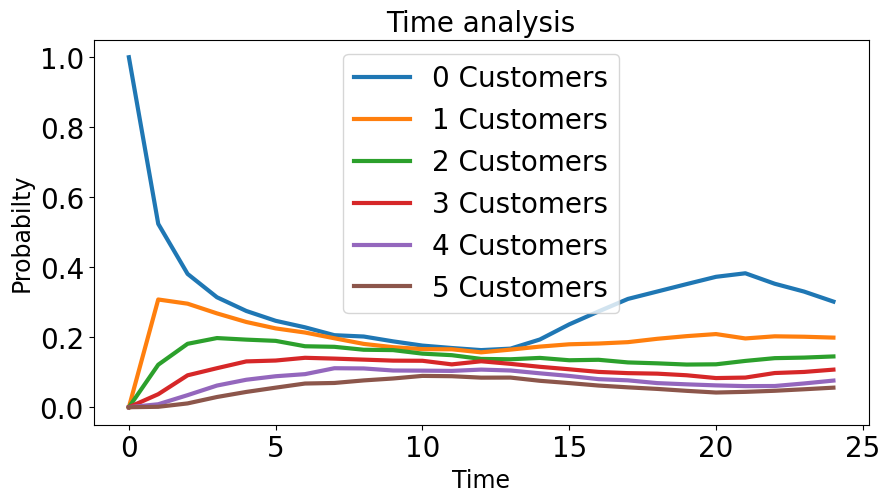

In [21]:
       
plt.figure(figsize=(10,5))
for num_cust in range(6):
    plt.plot(np.arange(prob_queue_arr.shape[0]), prob_queue_arr[:,num_cust], label = str(num_cust)+' Customers', linewidth=3)
plt.legend()
plt.title('Time analysis', fontsize = 20)
plt.xlabel('Time', fontsize = 17)
plt.ylabel('Probabilty', fontsize = 17)
plt.show()

<div dir="rtl">

### נחשב תוחלת מספר הצרכנים כפוקציה של הזמן

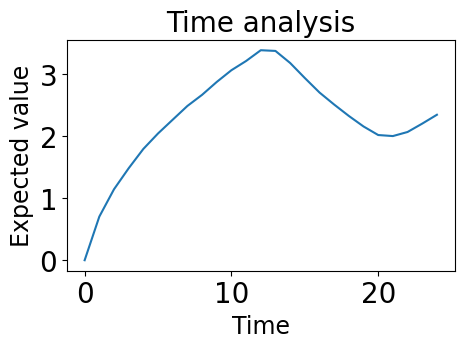

In [26]:
plt.figure(figsize=(5,3))
plt.plot(np.arange(prob_queue_arr.shape[0]), (np.arange(prob_queue_arr.shape[1])*prob_queue_arr).sum(axis=1))
plt.title('Time analysis', fontsize = 20)
plt.xlabel('Time', fontsize = 17)
plt.ylabel('Expected value', fontsize = 17)
plt.show()